# Л1 — Підготовка даних

Велика частина роботи в Data Science — збір і підготовка даних. Саме тут виникає багато неочікуваних проблем і пасток.

Ноутбук нижче базово показує, як працювати з даними й готувати їх. Він не охоплює всіх можливих сценаріїв, а приклади в ньому часом сильно спрощені. Проте він дасть розуміння, де шукати помилки і як з ними боротися. Більше туторіалів — у [Kaggle Learn](https://www.kaggle.com/learn), зокрема [Data Cleaning](https://www.kaggle.com/learn/data-cleaning).

Базовий алгоритм підготовки даних може виглядати так (у дужках — кроки цього ноутбука):

- зчитування даних і початкове дослідження (1);
- дослідження структури й особливостей даних, зміна типів (2);
- об'єднання даних з різних джерел (3–4);
- робота з пропущеними й зламаними значеннями: drop, fill тощо (5, 7, 8);
- пошук outliers: drop, clip тощо (6);
- пошук зайвих і бракуючих колонок (9).

І головне: з кожною дією треба бути обережним. Outliers можуть бути реальними даними, які логічно пояснюються і які не можна видаляти. А пропущені значення можуть щось означати й бути корисними. Обидва випадки є в цій роботі.

Далі бувають кроки, специфічні для певних моделей чи алгоритмів:

- scaling: normalization, standardization тощо;
- обробка категорійних колонок: one-hot encoding тощо;
- dimensionality reduction.

Тут вони не розглядаються, частину з них побачите в Л2 і Л3.

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Опис даних і таблиця недоліків — у `README.md`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

## 1. Завантаження даних

На цьому етапі важливо впевнитися, що файли завантажено правильно, і подивитися, що взагалі всередині. Можуть допомогти `df.head()`, `df.tail()`, `df.shape` і `df.dtypes`.

Що ви маєте зрозуміти?

- Чи зчиталися дані взагалі?
- Чи правильно розпарсилися рядки, колонки й значення?
- Які типи в колонок?
- Які приблизно значення?
- Скільки рядків і колонок?

In [2]:
# TODO: завантажте meters.parquet і registry.csv свого варіанта з папки variants/<варіант>/
df_meters = pd.read_parquet("meters.parquet")
df_registry = pd.read_csv("registry.csv")

print("meters.parquet", df_meters.shape)
print("registry.csv", df_registry.shape)

display(df_meters)
display(df_registry)

meters.parquet (526589, 4)
registry.csv (800, 7)


,meter_id,ts,consumption_kwh,record_ts
0,UA100507,2026-01-05 00:00:00,1.2632,2026-01-05 00:01:12
1,UA100507,2026-01-05 01:00:00,1.1168,2026-01-05 01:13:21
2,UA100507,2026-01-05 02:00:00,0.9488,2026-01-05 02:02:31
3,UA100507,2026-01-05 03:00:00,1.0152,2026-01-05 03:02:20
4,UA100507,2026-01-05 04:00:00,1.0000,2026-01-05 04:01:38
...,...,...,...,...
526584,UA994475,2026-02-01 19:00:00,1.8986,2026-02-01 19:03:45
526585,UA994475,2026-02-01 20:00:00,1.1533,2026-02-01 20:04:13
526586,UA994475,2026-02-01 21:00:00,0.9094,2026-02-01 21:08:00
526587,UA994475,2026-02-01 22:00:00,0.5154,2026-02-01 22:01:41


,meter_id,customer_type,tariff,electric_heating,connection_year,years_connected,district
0,UA100507,household,single,1,2020,5,darnytsia
1,UA101286,household,single,0,1995,30,Obolon
2,UA101953,industrial,dual_zone,0,1989,36,Solomianka
3,UA103011,household,single,0,1995,30,Obolon
4,UA106590,small_business,single,0,2014,12,Solomianka
...,...,...,...,...,...,...,...
795,UA985086,household,single,0,2024,1,Sviatoshyn
796,UA988617,industrial,single,0,1985,41,Sviatoshyn
797,UA988656,small_business,dual_zone,0,2019,7,Obolon
798,UA988767,household,dual_zone,1,2007,18,Solomianka


## 2. Звірка з описом

Іноді бізнес надає опис ідеальних даних, але реальні дані часто з ним не збігаються. Тому спершу подивіться, чи ваші дані відповідають опису в `README.md`. Може допомогти `df.describe()`.

Перевірте (але поки не виправляйте):

- типи колонок: якщо число прочиталося як текст, частина операцій спрацює неправильно;
- скільки рядків мають `customer_type`, `tariff` чи `electric_heating`, яких немає в описі;
- скільки рядків мають `ts`, `connection_year` чи `years_connected` поза межами з опису;
- скільки різних лічильників у кожному файлі — мають бути по 800.

Можуть допомогти `isin`, `between` і `nunique`.

Недоліки з таблиці в `README.md` перевірятимете далі, кожен у своєму кроці. Межі споживання залежать від типу абонента, а тип є лише в реєстрі, тому їх перевірите після об'єднання, на кроці 6.

In [3]:
# TODO: звірте дані з описом
print("Параметри даних meters.parquet")
print("-"*35)
print("Кількість унікальних лічильників: ", df_meters["meter_id"].nunique())
print(df_meters.dtypes)
print("-"*35 + "\n")

print("Параметри даних registry.csv")
print("-"*35)
print("Кількість унікальних лічильників: ", df_registry["meter_id"].nunique())
print(df_registry.dtypes)
print("-"*35 + "\n")

print("Кількість рядків з customer_type не зі списку: ", (~df_registry["customer_type"].isin(["household", "small_business", "industrial"])).sum())
print("Кількість рядків з tariff не зі списку: ", (~df_registry["tariff"].isin(["single", "dual_zone"])).sum())
print("Кількість рядків з electric_heating не зі списку: ", (~df_registry["electric_heating"].isin([0, 1])).sum())

print("Кількість рядків з ts поза допустимими межами: ", (~df_meters["ts"].between("2026-01-05 00:00", "2026-02-01 23:00")).sum())
print("Кількість рядків з connection_year поза допустимими межами: ", (~df_registry["connection_year"].between(1985,	2024)).sum())
print("Кількість рядків з years_connected поза допустимими межами: ", (~df_registry["years_connected"].between(1, 41)).sum())



Параметри даних meters.parquet
-----------------------------------
Кількість унікальних лічильників:  800
meter_id                      str
ts                 datetime64[us]
consumption_kwh           float64
record_ts          datetime64[us]
dtype: object
-----------------------------------

Параметри даних registry.csv
-----------------------------------
Кількість унікальних лічильників:  800
meter_id              str
customer_type         str
tariff                str
electric_heating    int64
connection_year     int64
years_connected     int64
district              str
dtype: object
-----------------------------------

Кількість рядків з customer_type не зі списку:  0
Кількість рядків з tariff не зі списку:  0
Кількість рядків з electric_heating не зі списку:  0
Кількість рядків з ts поза допустимими межами:  0
Кількість рядків з connection_year поза допустимими межами:  0
Кількість рядків з years_connected поза допустимими межами:  0


## 3. Реєстр: номери й райони (D-E, D-F)

Дані зберігаються в різних системах, тому формат ідентифікатора може не збігатися: `" UA123456"` для pandas — інший номер, ніж `UA123456`. Наївний join призведе до того, що частина даних втратиться. Так само `podil` і `Podil` — різні райони, і будь-який підрахунок по районах буде хибним.

Для D-E і D-F виведіть, скільки рядків реєстру зіпсовано, і виправте їх так, як сказано в таблиці недоліків. Можуть допомогти `str.fullmatch(r"UA\d{6}")`, `isin`, `str.strip()`, `str.lstrip("0")` і `str.capitalize()`.

In [4]:
# TODO: D-E — виведіть кількість зіпсованих номерів і виправте meter_id у реєстрі
print("Кількість зіпсованих номерів лічильників у meters.parquet", (~df_meters["meter_id"].str.fullmatch(r"UA\d{6}")).sum())
print("Кількість зіпсованих номерів лічильників у registry.csv", (~df_registry["meter_id"].str.fullmatch(r"UA\d{6}")).sum())

df_registry["meter_id"] = df_registry["meter_id"].str.strip().str.lstrip("0")

print("Кількість зіпсованих номерів лічильників у registry.csv після правок", (~df_registry["meter_id"].str.fullmatch(r"UA\d{6}")).sum())

print("-"*60)
# TODO: D-F — виведіть кількість рядків, де district написано не як в описі, і виправте
print("Кількість записів з неправильним районом у registry.csv", (~df_registry["district"].isin(["Podil", "Solomianka", "Darnytsia", "Obolon", "Sviatoshyn"])).sum())

df_registry["district"] = df_registry["district"].str.strip().str.capitalize()

print("Кількість записів з неправильним районом у registry.csv після правок", (~df_registry["district"].isin(["Podil", "Solomianka", "Darnytsia", "Obolon", "Sviatoshyn"])).sum())

Кількість зіпсованих номерів лічильників у meters.parquet 0
Кількість зіпсованих номерів лічильників у registry.csv 96
Кількість зіпсованих номерів лічильників у registry.csv після правок 0
------------------------------------------------------------
Кількість записів з неправильним районом у registry.csv 80
Кількість записів з неправильним районом у registry.csv після правок 0


## 4. Об'єднання

Тепер погодинні дані можна об'єднати з реєстром за `meter_id` (join, у pandas — `merge`). pandas не попереджає, коли рядок не знайшов пари, тому якість об'єднання треба перевірити самому.

Об'єднану таблицю назвіть `df`, з нею працюватимете далі. Перевірте й виведіть:

- кількість рядків до і після об'єднання — вона не має змінитися;
- кількість рядків без атрибутів абонента (пропуск у `customer_type`) — має бути 0.

Може допомогти `merge(..., how="left", validate="m:1")`: `validate` ще й перевірить, що кожному лічильнику відповідає один рядок реєстру.

In [5]:
# TODO: об'єднайте погодинні дані з реєстром і перевірте об'єднання
print("Кількість записів meters.parquet до об'єднання: ", df_meters.shape[0])

df: pd.DataFrame = df_meters.merge(df_registry, on='meter_id', how='left', validate='m:1')

print("Кількість записів у df: ", df.shape[0])

display(df)

Кількість записів meters.parquet до об'єднання:  526589
Кількість записів у df:  526589


,meter_id,ts,consumption_kwh,record_ts,customer_type,tariff,electric_heating,connection_year,years_connected,district
0,UA100507,2026-01-05 00:00:00,1.2632,2026-01-05 00:01:12,household,single,1,2020,5,Darnytsia
1,UA100507,2026-01-05 01:00:00,1.1168,2026-01-05 01:13:21,household,single,1,2020,5,Darnytsia
2,UA100507,2026-01-05 02:00:00,0.9488,2026-01-05 02:02:31,household,single,1,2020,5,Darnytsia
3,UA100507,2026-01-05 03:00:00,1.0152,2026-01-05 03:02:20,household,single,1,2020,5,Darnytsia
4,UA100507,2026-01-05 04:00:00,1.0000,2026-01-05 04:01:38,household,single,1,2020,5,Darnytsia
...,...,...,...,...,...,...,...,...,...,...
526584,UA994475,2026-02-01 19:00:00,1.8986,2026-02-01 19:03:45,household,single,0,2000,25,Solomianka
526585,UA994475,2026-02-01 20:00:00,1.1533,2026-02-01 20:04:13,household,single,0,2000,25,Solomianka
526586,UA994475,2026-02-01 21:00:00,0.9094,2026-02-01 21:08:00,household,single,0,2000,25,Solomianka
526587,UA994475,2026-02-01 22:00:00,0.5154,2026-02-01 22:01:41,household,single,0,2000,25,Solomianka


## 5. Повторні відправки (D-C)

Повторна відправка — та сама година того самого лічильника ще раз, іноді з уточненим значенням. Якщо лишити обидва записи, споживання за цю годину подвоїться. Лишаємо найпізніший за `record_ts` запис як найсвіжіший.

Виведіть кількість рядків і кількість різних пар `meter_id` і `ts`, потім зніміть повтори. Можуть допомогти `duplicated(["meter_id", "ts"])`, `sort_values("record_ts")` і `drop_duplicates(["meter_id", "ts"], keep="last")`.

In [6]:
# TODO: D-C — виведіть обидві кількості й лиште для кожної пари найпізніший запис
print(f"Кількість рядків {df.shape[0]}, кількість унікальних пар {(~df.duplicated(["meter_id", "ts"])).sum()}")

df = df.sort_values("record_ts").drop_duplicates(["meter_id", "ts"], keep="last")

print(f"Кількість рядків {df.shape[0]}, кількість унікальних пар {(~df.duplicated(["meter_id", "ts"])).sum()} після видалення")

Кількість рядків 526589, кількість унікальних пар 516338
Кількість рядків 516338, кількість унікальних пар 516338 після видалення


## 6. Одиниці виміру (D-D)

Значення у Вт·год схожі на викиди, але це не шум, а помилка одиниць. Якщо їх видалити, зникнуть цілі абоненти.

1. Для кожного лічильника порахуйте відношення його медіани `consumption_kwh` до медіани всіх рядків його `customer_type`. Більше 100 — лічильник звітує у Вт·год.
2. Побудуйте графік медіан лічильників за `customer_type` з логарифмічною віссю, наприклад boxplot.
3. Виведіть кількість лічильників у Вт·год, найбільше відношення серед решти лічильників і найменше серед лічильників у Вт·год (якщо таких немає — лише найбільше відношення серед усіх). Ці числа — доказ у звіті: вони показують, наскільки далеко від порога обидві групи.
4. Поділіть значення цих лічильників на 1000 і виведіть, скільки рядків поза межами споживання з опису, — має бути 0.

Можуть допомогти `DataFrame.boxplot(column=..., by="customer_type")`, `plt.yscale("log")` і `between`. Клітинку з діленням не запускайте двічі: значення поділяться ще раз. Якщо так сталося, перезапустіть ноутбук з початку.

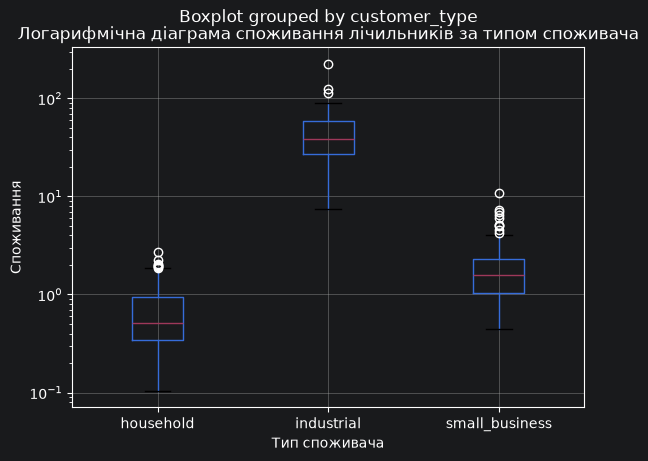

Кількість лічильників, що звітують у Вт*год:  0
Найбільше значення серед лічильників, що звітують не у Вт*год:  6.716069321075843


In [7]:
# TODO: D-D
meter_median = df.groupby("meter_id")["consumption_kwh"].median()  # медіана кожного лічильника
meter_type = df.groupby("meter_id")["customer_type"].first()   # customer_type кожного лічильника
type_median = df.groupby("customer_type")["consumption_kwh"].median() # медіана всіх рядків кожного customer_type
ratio = meter_median / meter_type.map(type_median)

plot_data = pd.DataFrame({ "consumption_kwh": meter_median, "customer_type": meter_type })
plot_data.boxplot(column="consumption_kwh", by="customer_type")
plt.yscale("log")
plt.title("Логарифмічна діаграма споживання лічильників за типом споживача")
plt.xlabel("Тип споживача")
plt.ylabel("Споживання")
plt.show()

w_h_meters = ratio[ratio > 100]
w_h_num = len(w_h_meters)


print("Кількість лічильників, що звітують у Вт*год: ", w_h_num)
print("Найбільше значення серед лічильників, що звітують не у Вт*год: ", ratio[ratio <= 100].max())
if w_h_num > 0:
    print("Найменше значення серед лічильників, що звітують у Вт*год: ", w_h_meters.min())

    df.loc[df["meter_id"].isin(w_h_meters.index),"consumption_kwh"] /= 1000

    meter_median = df.groupby("meter_id")["consumption_kwh"].median()
    meter_type = df.groupby("meter_id")["customer_type"].first()
    type_median = df.groupby("customer_type")["consumption_kwh"].median()
    ratio = meter_median / meter_type.map(type_median)

    print("Кількість лічильників, що звітують у Вт*год після виправлень: ", (ratio > 100).sum())


## 7. Лічильники, що замовкли (D-A)

Пропуски не заповнюємо: те, що лічильник замовк, уже є інформацією про можливу відмову, а середнє її стерло б. Не видаляємо теж: до відмови лічильник передавав правильні дані.

Для кожного лічильника порахуйте, скільки годин минуло від його останнього `ts` до `2026-02-01 23:00`; більше 48 — замовк. Як на кроці 6, виведіть кількість замовклих, найбільшу тишу серед решти й найменшу серед замовклих (якщо замовклих немає — лише найбільшу тишу серед усіх).

Номери замовклих лічильників збережіть списком `silent`, наприклад `list(....index)`: він знадобиться в регресії.

Можуть допомогти `pd.Timestamp("2026-02-01 23:00")` і `/ pd.Timedelta(hours=1)`.

In [8]:
# TODO: D-A

last_info = df.groupby("meter_id")["ts"].max()

silent_time = (pd.Timestamp("2026-02-01 23:00") - last_info) / pd.Timedelta(hours=1)
silent_list = silent_time[silent_time > 48]
silent_num = len(silent_list)
silent = []

print("Кількість лічильників, що замовкли: ", silent_num)
print("Найбільше значення тиші серед лічильників, що звітують ", silent_time[silent_time <= 48].max())
if silent_num > 0:
    print("Найменше значення тиші лічильників, що замовкли: ", silent_list.min())
    silent = list(silent_list.index)

Кількість лічильників, що замовкли:  48
Найбільше значення тиші серед лічильників, що звітують  1.0
Найменше значення тиші лічильників, що замовкли:  149.0


## 8. Завмерлі лічильники (D-B)

Завмерлі значення виглядають правдоподібно, і ні середнє, ні максимум їх не видають. Помітно лише те, що значення перестали змінюватися. Такі лічильники не видаляємо: частина їхніх годин справна.

Для кожного лічильника порахуйте частку різних значень `consumption_kwh` серед його записів; менше 0.65 — завмер. Побудуйте гістограму цієї частки по лічильниках. Як на кроці 6, виведіть кількість завмерлих, найменшу частку серед решти й найбільшу серед завмерлих (якщо завмерлих немає — лише найменшу частку серед усіх).

Номери завмерлих лічильників збережіть списком `frozen`: він знадобиться в регресії.

Можуть допомогти `nunique()`, `size()` і `plt.hist`.

Кількість лічильників, що завмерли:  40
Найменше значення частки серед лічильників, що не завмерли  0.8396369137670197
Найбільше значення частки серед завмерлих лічильників:  0.4992412746585736


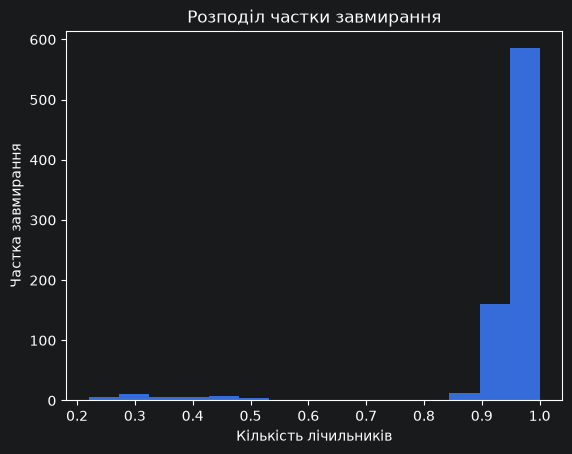

In [9]:
# TODO: D-B

grouped_consumption = df.groupby("meter_id")["consumption_kwh"]

freeze_rate = grouped_consumption.nunique() / grouped_consumption.size()

frozen_list = freeze_rate[freeze_rate < 0.65]
frozen_num = len(frozen_list)
frozen = []

print("Кількість лічильників, що завмерли: ", frozen_num)
print("Найменше значення частки серед лічильників, що не завмерли ", freeze_rate[freeze_rate >= 0.65].min())
if frozen_num > 0:
    print("Найбільше значення частки серед завмерлих лічильників: ", frozen_list.max())
    frozen = list(frozen_list.index)

plt.hist(freeze_rate, bins=15)
plt.title("Розподіл частки завмирання")
plt.ylabel("Частка завмирання")
plt.xlabel("Кількість лічильників")
plt.show()


## 9. Кореляції

Колонка, що майже копіює іншу, не додає інформації: у кластеризації вона подвоює вагу того самого фактора, а в регресії робить коефіцієнти нестабільними. Технічна колонка `record_ts` після кроку 5 теж не потрібна.

Порахуйте кореляції між числовими колонками об'єднаної таблиці. Пару з кореляцією за модулем понад 0.95 вважайте копією і лиште з неї одну колонку. Приберіть `record_ts`. Підсумкову таблицю назвіть `result`.

Можуть допомогти `select_dtypes("number").corr().abs()` і `drop(columns=...)`.

In [10]:
# TODO: знайдіть і приберіть колонку-копію та record_ts
corr_tab = df.select_dtypes("number").corr().abs()

duplicates = []
for a in corr_tab.columns:
    for b in corr_tab.index:
        if a < b and corr_tab.loc[a, b] > 0.95:
            duplicates.append((a, b, corr_tab.loc[a, b]))

result = df.drop(columns=["record_ts"])

for a, b, corr in duplicates:
    print("Колонки дублікати: ", a, b)
    print("Кореляція: ", corr)
    result = result.drop(columns=[b])

display(result)

Колонки дублікати:  connection_year years_connected
Кореляція:  0.9990647532915936


,meter_id,ts,consumption_kwh,customer_type,tariff,electric_heating,connection_year,district
474278,UA920541,2026-01-05 00:00:00,0.1837,household,single,0,1986,Sviatoshyn
411954,UA807490,2026-01-05 00:00:00,0.0900,household,single,0,2013,Obolon
150344,UA368344,2026-01-05 00:00:00,0.1712,household,single,0,2010,Darnytsia
180231,UA422875,2026-01-05 00:00:00,0.1026,household,single,0,2021,Sviatoshyn
363950,UA714944,2026-01-05 00:00:00,1.7585,household,dual_zone,1,2005,Solomianka
...,...,...,...,...,...,...,...,...
162217,UA390644,2026-02-01 22:00:00,0.6106,household,single,0,2006,Darnytsia
22773,UA140855,2026-02-01 22:00:00,0.8300,household,dual_zone,1,2020,Obolon
445004,UA856382,2026-02-01 23:00:00,13.5280,industrial,dual_zone,0,1991,Darnytsia
177520,UA414313,2026-02-01 23:00:00,0.3609,small_business,dual_zone,0,1991,Darnytsia


## 10. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [11]:
districts = ["Podil", "Solomianka", "Darnytsia", "Obolon", "Sviatoshyn"]
min_kwh = {"household": 0.01, "small_business": 0.02, "industrial": 1}
max_kwh = {"household": 10, "small_business": 60, "industrial": 1200}
corr = result.select_dtypes("number").corr().abs()
copies = [(a, b) for a in corr for b in corr if a < b and corr.loc[a, b] > 0.95]

assert not result.duplicated(["meter_id", "ts"]).any(), "лишилися повтори лічильник–година"
assert result["meter_id"].nunique() == 800, "лічильників має бути 800"
assert result["meter_id"].str.fullmatch(r"UA\d{6}").all(), "є номери не у форматі UA і 6 цифр"
assert result["customer_type"].notna().all(), "є рядки без атрибутів абонента"
assert result["district"].isin(districts).all(), "є райони, яких немає в описі"
assert result["consumption_kwh"].between(result["customer_type"].map(min_kwh), result["customer_type"].map(max_kwh)).all(), "є споживання поза межами з опису"
assert not copies, f"лишилися колонки-копії: {copies}"
assert "record_ts" not in result, "технічна колонка record_ts лишилася"

result.to_parquet("cleaned.parquet", index=False)
print("усе гаразд:", result.shape)

усе гаразд: (516338, 8)


## 11. Регресія

Регресію часто використовують, щоб передбачати певні показники. Проте лінійна регресія також показує, як кожен показник впливає на результат. Це і є регресійний аналіз.

Для прикладу подивимося, як на добове споживання домогосподарства впливають електроопалення і двозонний тариф: `y = a + b₁·x₁ + b₂·x₂`.

- `y` — середнє споживання лічильника за добу, кВт·год;
- `x₁` — `electric_heating`, `x₂` — двозонний тариф (обидва 0 або 1);
- `b₁` і `b₂` — на скільки кВт·год на добу більше споживає абонент із цим фактором за однакового іншого;
- `a` — споживання без опалення на звичайному тарифі;
- R² — яку частку розкиду споживання пояснюють обидва фактори, від 0 до 1.

Регресія тут краща за просте порівняння середніх: двозонний тариф здебільшого мають будинки з опаленням, і різниця середніх за тарифом приписала б тарифу ще й споживання на опалення.

Нормалізація не потрібна: обидва фактори мають однаковий масштаб (0 або 1), тож `b₁` і `b₂` можна порівнювати напряму, а `y` лишається в кВт·год на добу, і коефіцієнти легко пояснити. Якби фактори мали різні одиниці, наприклад площу і рік, для порівняння впливу їх спершу стандартизували б.

Лічильники з `silent` і `frozen` не беремо: у `cleaned.parquet` вони лишаються, але їхнє середнє споживання спотворене.

Код майже готовий: допишіть `homes` і запустіть.

In [12]:
# TODO: homes — рядки result для домогосподарств без лічильників із silent і frozen
# кожну умову беріть у дужки: result[(умова 1) & ~(умова 2)]
homes = result[~(result["meter_id"].isin(silent)) & ~(result["meter_id"].isin(frozen)) & (result["customer_type"] == "household")]

per_meter = homes.groupby("meter_id").agg(
    kwh_per_day=("consumption_kwh", "mean"),
    electric_heating=("electric_heating", "first"),
    tariff=("tariff", "first"),
)
per_meter["kwh_per_day"] *= 24
per_meter["dual_zone"] = (per_meter["tariff"] == "dual_zone").astype(int)

x, y = per_meter[["electric_heating", "dual_zone"]], per_meter["kwh_per_day"]
model = LinearRegression().fit(x, y)
print("лічильників:", len(per_meter))
print(f"a = {model.intercept_:.2f}, b₁ (опалення) = {model.coef_[0]:.2f}, b₂ (двозонний тариф) = {model.coef_[1]:.2f}, R² = {model.score(x, y):.3f}")

лічильників: 453
a = 11.10, b₁ (опалення) = 17.41, b₂ (двозонний тариф) = 2.49, R² = 0.671
